# 02 A first neural network: an MLP on the pixels

**Goal of this notebook.** We build our first model for the museum guide: a **feed-forward
network**, also called **MLP** (multi-layer perceptron). It is the network of the course: a chain
of layers where each neuron is connected to all the values of the layer before it.

- **Input**: the pixels of the painting, shrunk to 64 x 64 x 3 colours = 12 288 numbers.
- **Hidden layers**: 512 then 256 neurons, with the ReLU activation, $\max(0, z)$.
- **Output**: 5 scores (logits), one per style. The highest score is the prediction.

Before we trust a training run, we do the two checks of the course: (1) the first loss must be
close to $\ln 5$, and (2) the model must be able to learn one small batch by heart. Then we train a
**baseline** (a first reference model that the next notebooks try to beat) and we test three image
sizes.

We only use the **train** and **validation** images here. The test set stays locked.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import math

import matplotlib.pyplot as plt
import pandas as pd
import torch

from museum_guide.config import FAST_RUN, set_seed
from museum_guide.data import load_split_tensors
from museum_guide.diagnostics import chance_loss, initial_loss, overfit_one_batch
from museum_guide.evaluation import save_results
from museum_guide.models import count_parameters, init_weights, make_mlp, mlp_parameters
from museum_guide.plots import PALETTE, plot_compare, plot_history, save_figure
from museum_guide.training import fit, make_loaders, summary

set_seed()
EPOCHS = 10 if FAST_RUN else 40
SEEDS = [0] if FAST_RUN else [0, 1, 2]
print("FAST_RUN:", FAST_RUN, "| epochs:", EPOCHS, "| seeds:", SEEDS, "| CPU threads:", torch.get_num_threads())

FAST_RUN: False | epochs: 40 | seeds: [0, 1, 2] | CPU threads: 8


## 1. The data as tensors

**What we do.** We load the images at 64 x 64 pixels and **standardise** them: for each colour
channel we subtract the mean and divide by the standard deviation. These two numbers come from the
**training images only**; the validation images use the same numbers, as new paintings will.

In [2]:
data, meta = load_split_tensors(64)
X_train, y_train = data["train"]
X_val, y_val = data["val"]
print("train", tuple(X_train.shape), "| validation", tuple(X_val.shape))
print("train mean per channel", X_train.mean(dim=(0, 2, 3)).round(decimals=3).tolist(),
      "| std", X_train.std(dim=(0, 2, 3)).round(decimals=3).tolist())
print("val   mean per channel", X_val.mean(dim=(0, 2, 3)).round(decimals=3).tolist(),
      "| std", X_val.std(dim=(0, 2, 3)).round(decimals=3).tolist())
majority = y_val.bincount().max().item() / len(y_val)
print(f"always answering the most frequent style gives {majority:.3f} accuracy on validation")

train (1061, 3, 64, 64) | validation (219, 3, 64, 64)
train mean per channel [-0.0, 0.0, -0.0] | std [1.0, 1.0, 1.0]
val   mean per channel [-0.0860000029206276, -0.10199999809265137, -0.08900000154972076] | std [0.9940000176429749, 0.968999981880188, 0.9480000138282776]
always answering the most frequent style gives 0.228 accuracy on validation


## 2. The model

**What we do.** We build the MLP from `nn.Linear` layers (the building block of the course) and we
count its parameters, by PyTorch and by the formula of session 3: a layer with $n^{[l]}$ neurons and
$n^{[l-1]}$ inputs has $n^{[l]}(n^{[l-1]} + 1)$ parameters.

In [3]:
torch.manual_seed(0)
model = make_mlp(3 * 64 * 64, hidden=(512, 256), n_out=5)
n_params = count_parameters(model)
assert n_params == mlp_parameters(12_288, (512, 256), 5) == 6_424_581
print(model)
print(f"{n_params:,} parameters for {len(X_train):,} training images "
      f"({n_params / len(X_train):,.0f} parameters per image)")

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=12288, out_features=512, bias=True)
  (2): ReLU()
  (3): Linear(in_features=512, out_features=256, bias=True)
  (4): ReLU()
  (5): Linear(in_features=256, out_features=5, bias=True)
)
6,424,581 parameters for 1,061 training images (6,055 parameters per image)


## 3. Check 1: the first loss

**What we do.** Before training, the model knows nothing. The best it can honestly do is to give
each style the same probability, 1/5. The cross-entropy loss is then $-\ln(1/5) = \ln 5 = 1.609$.
We measure the first loss with the usual He initialisation, then with the weights of the **last
layer** multiplied by 0.1.

In [4]:
first_loss = {}
for scale in (1.0, 0.1):
    torch.manual_seed(0)
    m = init_weights(make_mlp(3 * 64 * 64), kind="he", last_scale=scale)
    first_loss[f"last_scale_{scale}"] = initial_loss(m, X_train, y_train)
    with torch.no_grad():
        logit_std = m(X_train).std().item()
    print(f"last layer x {scale}: first loss {first_loss[f'last_scale_{scale}']:.3f} "
          f"(ln 5 = {chance_loss(5):.3f}), std of the first logits {logit_std:.2f}")

last layer x 1.0: first loss 1.990 (ln 5 = 1.609), std of the first logits 1.34


last layer x 0.1: first loss 1.591 (ln 5 = 1.609), std of the first logits 0.13


**What we see.** With the usual He initialisation, the first loss is **1.990**, clearly above
$\ln 5 = 1.609$. The first logits are too large (standard deviation 1.34), so the untrained model
is already confident, and wrong 4 times out of 5.

When we multiply the last layer by 0.1, the logits shrink (standard deviation 0.13) and the first
loss is **1.591**, almost exactly $\ln 5$. The model now starts as it should, saying "I don't know".
We keep this initialisation for all our MLPs.

## 4. Check 2: learn one small batch by heart

**What we do.** We take only 32 training images and train on them again and again (150 steps).
A healthy model and a correct training loop must reach a loss near 0 and 100 % accuracy on these 32
images. If it cannot, there is a bug, and it is useless to go further.

loss 1.537 -> 0.0000, accuracy on the batch 100%


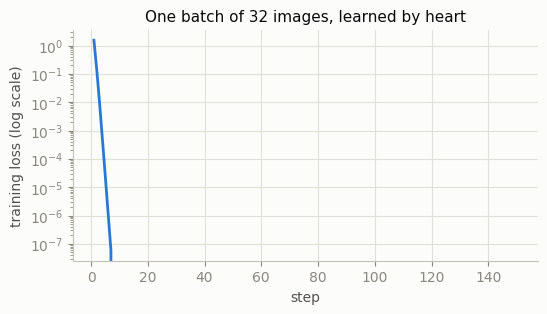

In [5]:
torch.manual_seed(0)
m = init_weights(make_mlp(3 * 64 * 64), last_scale=0.1)
xb, yb = X_train[:32], y_train[:32]
losses, acc_batch = overfit_one_batch(m, xb, yb, torch.optim.Adam(m.parameters(), lr=1e-3), steps=150)
print(f"loss {losses[0]:.3f} -> {losses[-1]:.4f}, accuracy on the batch {acc_batch:.0%}")
assert acc_batch == 1.0, "the model cannot even learn 32 images: look for a bug"

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(range(1, len(losses) + 1), losses, color=PALETTE[0])
ax.set_yscale("log")
ax.set_xlabel("step")
ax.set_ylabel("training loss (log scale)")
ax.set_title("One batch of 32 images, learned by heart")
save_figure(fig, "02_overfit_one_batch")
plt.show()

**What we see.** The loss goes from 1.537 to almost 0, and the 32 images are 100 % correct. The model
is big enough and the 5 lines of the training loop (zero_grad, forward, loss, backward, step) work.
This check says nothing about new paintings: that is the next question.

## 5. The baseline: train on all the training images

**What we do.** We train the MLP on the 1 061 training images for 40 epochs (one epoch = one
pass over all the training images), with mini-batches of 64 images and the **Adam** optimiser at
its usual learning rate, 0.001. No regularisation yet: this is our **baseline**.

After each epoch we measure loss and accuracy on the training set **and** on the validation set,
both in evaluation mode, so that the two curves are comparable.

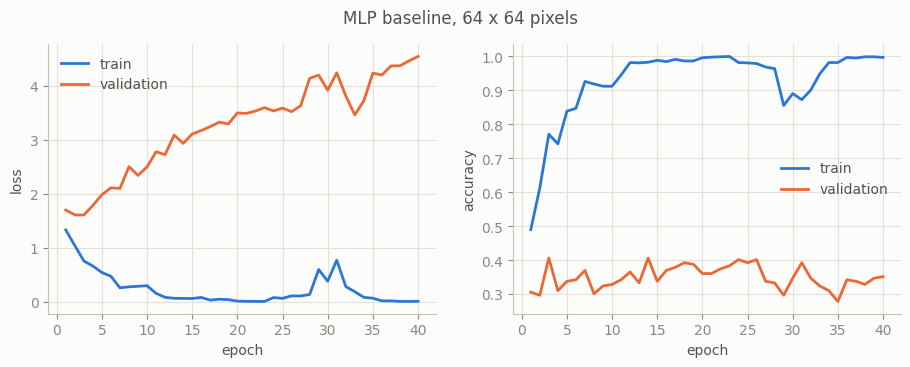

epochs_run           40.000
final_train_acc       0.997
final_val_acc         0.352
final_gap             0.646
seconds_per_epoch     0.382
best_epoch            3.000
best_val_loss         1.606
val_acc_at_best       0.406
gap_at_best           0.365
dtype: float64

In [6]:
loaders64 = make_loaders(X_train, y_train, X_val, y_val, batch_size=64)


def train_mlp(loaders, n_in, seed=0, lr=1e-3, epochs=EPOCHS):
    torch.manual_seed(seed)  # same initial weights for the same seed
    model = init_weights(make_mlp(n_in), last_scale=0.1)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    return model, fit(model, optimizer, loaders, epochs, seed=seed + 1)


model_base, history_base = train_mlp(loaders64, 3 * 64 * 64)
plot_history(history_base, "MLP baseline, 64 x 64 pixels", save_as="02_baseline_curves")
base = summary(history_base)
pd.Series(base).round(3)

**What we see.** This is the classic picture of **overfitting**: the model learns the training
images by heart and fails on new ones.

- The training accuracy climbs to **99.7 %**: the model knows its 1 061 images by heart.
- The validation accuracy is best very early, **40.6 % at epoch 3**, then falls to 35.2 % at epoch 40.
- The validation loss is lowest at epoch 3 (1.606), then rises: the network becomes over-confident
  on paintings it has never seen.

40.6 % is almost twice the majority answer (22.8 %), so the MLP does learn something. But it is far
from what a museum guide needs. With 6 055 parameters per training image, this is not a surprise:
the model has much more capacity than data. One epoch takes 0.28 s on the CPU.

## 6. Which image size?

**What we do.** A smaller image means fewer inputs, so fewer parameters and a faster model, but
also fewer details. We compare 16 x 16, 32 x 32 and 64 x 64 pixels.

The validation set has only 219 images, so one run is a **noisy measure**: the accuracy can move by
a few points just because of the random initial weights. We train each size with 3 different
seeds and report the mean and the standard deviation.

In [7]:
rows, curves = [], {}
for size in (16, 32, 64):
    d, _ = load_split_tensors(size)
    loaders = make_loaders(*d["train"], *d["val"], batch_size=64)
    for seed in SEEDS:
        m, h = train_mlp(loaders, 3 * size * size, seed=seed)
        rows.append({"size": size, "seed": seed, "parameters": count_parameters(m), **summary(h)})
        if seed == 0:
            curves[f"{size} x {size}"] = h

sizes = pd.DataFrame(rows)
size_table = sizes.groupby("size").agg(
    parameters=("parameters", "first"),
    best_epoch=("best_epoch", "mean"),
    val_acc_mean=("val_acc_at_best", "mean"), val_acc_std=("val_acc_at_best", "std"),
    best_val_loss=("best_val_loss", "mean"),
    final_gap=("final_gap", "mean"),
    seconds_per_epoch=("seconds_per_epoch", "mean"),
)
size_table.round(3)

,parameters,best_epoch,val_acc_mean,val_acc_std,best_val_loss,final_gap,seconds_per_epoch
size,,,,,,,
16,526341,1.333,0.394,0.003,1.432,0.618,0.071
32,1705989,1.667,0.390,0.026,1.440,0.621,0.138
64,6424581,1.667,0.371,0.030,1.554,0.614,0.385


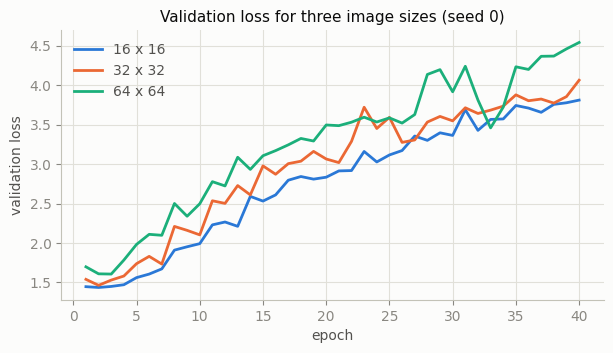

In [8]:
plot_compare(curves, "val_loss", "Validation loss for three image sizes (seed 0)", save_as="02_sizes_val_loss")

**What we see.** Smaller images do **not** hurt. At the best epoch, the mean over 3 seeds is:

- 16 x 16 pixels: **39.4 %** (standard deviation 0.3 points);
- 32 x 32 pixels: **39.0 %** (2.6 points);
- 64 x 64 pixels: **37.1 %** (3.0 points).

The accuracy differences are inside the noise, but the validation loss tells the same story: 1.43
at 16 px, 1.55 at 64 px. The best epoch is always the 1st, 2nd or 3rd.

More pixels give more parameters (from 0.5 to 6.4 million) and more ways to memorise, but no extra
style information that an MLP can use. An MLP sees the image as a flat list of numbers. It does not
know that two pixels are neighbours, so it cannot see shapes or brush strokes. The 16 x 16 model
is also 9 times faster per epoch (0.03 s against 0.27 s).

For the next notebook we keep **32 x 32 pixels**: as accurate as 16 x 16 within the noise, 3.8
times fewer parameters than 64 x 64, and still enough detail to flip the images (augmentation).

In [9]:
save_results("02_mlp", {
    "first_loss": first_loss, "ln5": chance_loss(5),
    "overfit_one_batch": {"first_loss": losses[0], "last_loss": losses[-1], "accuracy": acc_batch},
    "baseline_64px": {"parameters": n_params, **base},
    "majority_val_acc": majority,
    "sizes": size_table.reset_index().to_dict(orient="records"),
    "runs": sizes.to_dict(orient="records"),
})

WindowsPath('C:/Users/benca/OneDrive - Thelio/Documents/Perso/Albert School/Deep learning/neural-network-project/reports/results/02_mlp.json')

## What we learned

- **Both checks pass**: after shrinking the last layer, the first loss is 1.591, almost $\ln 5$,
  and the model learns one batch of 32 images by heart (100 %).
- **Baseline**: the MLP on 64 x 64 pixels (6.4 million parameters) reaches **40.6 %** validation
  accuracy at its best epoch (epoch 3). This is about twice the chance level, but the model
  overfits strongly: 99.7 % on the training images at the end, a gap of 0.65.
- **Image size**: 16, 32 or 64 pixels give 37 to 39 %, the same within the noise. More pixels
  mean more parameters, not better results.

**Next step** (notebook 03): watch the training more closely (gradients, activations, learning
rate), fight overfitting (weight decay, dropout, batch normalisation, early stopping, flips) and
diagnose broken runs.